In [1]:
import os

import pyzx

from qelebrimbor.formats.preprocessing.bialgebra_reduction import BialgebraReduction
from qelebrimbor.formats.preprocessing.full_reduction import FullReduction
from qelebrimbor.formats.preprocessing.no_more_than_four_edges import NoMoreThanFourEdges

os.environ["EXTRA_CLING_ARGS"] = "-Wno-nonportable-include-path"

import tempfile

from IPython.display import SVG, display
from ogdf_python import cppinclude, ogdf

from qelebrimbor.formats.ogdf import OGDF
from qelebrimbor.formats.pyzx import PYZX

cppinclude("ogdf/planarity/PlanarizationLayout.h")
cppinclude("ogdf/planarity/EmbedderMinDepthMaxFaceLayers.h")
cppinclude("ogdf/orthogonal/OrthoLayout.h")
cppinclude("ogdf/fileformats/GraphIO.h")

True

In [2]:
settings = ogdf.GraphIO.SVGSettings()
settings.fontColor("white")
settings.fontSize(8)


def print_layout(graph_attributes):
    with tempfile.NamedTemporaryFile(suffix=".svg", delete=True) as tmp:
        ogdf.GraphIO.drawSVG(graph_attributes, tmp.name, settings)
        display(SVG(tmp.name))

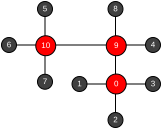

In [3]:
zxg = pyzx.Graph()
x = zxg.add_vertex(ty=pyzx.VertexType.X, qubit=1, row=3.5)
for i in range(8):
    b = zxg.add_vertex(ty=pyzx.VertexType.BOUNDARY, qubit=0, row=i)
    zxg.add_edge((x, b))
pyzx.draw(zxg, labels=True)
zxg = NoMoreThanFourEdges.process(zxg)

ogg, attributes, _ = OGDF.from_pyzx_graph(zxg)

for node in ogg.nodes:
    attributes.width[node] *= 20
    attributes.height[node] *= 20

algorithm = ogdf.PlanarizationLayout()
layout = ogdf.OrthoLayout()
layout.__python_owns__ = False  # Needed to avoid C++ segmentation fault when object is destroyed
layout.separation(20.0)
embedder = ogdf.EmbedderMinDepthMaxFaceLayers()
embedder.__python_owns__ = False
algorithm.setEmbedder(embedder)
algorithm.setPlanarLayouter(layout)

algorithm.call(attributes)

print_layout(attributes)

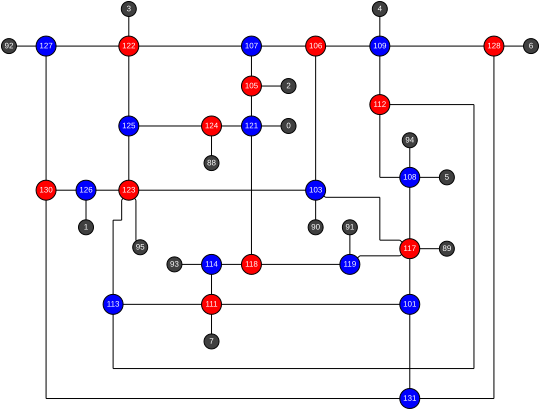

In [4]:
# Perform the layout computation for the fully-reduced, bi-algebraized ZX-graph
zxg = PYZX.from_file("../benchmarking/datasets/medio/identity/quick/random-cnots-q8-d32-s3746021966.pyzx.json")
zxg = FullReduction.process(zxg)
zxg = BialgebraReduction.process(zxg)
ogg, attributes, _ = OGDF.from_pyzx_graph(zxg)

for node in ogg.nodes:
    attributes.width[node] *= 20
    attributes.height[node] *= 20

algorithm = ogdf.PlanarizationLayout()
layout = ogdf.OrthoLayout()
layout.__python_owns__ = False  # Needed to avoid C++ segmentation fault when object is destroyed
layout.separation(20.0)
embedder = ogdf.EmbedderMinDepthMaxFaceLayers()
embedder.__python_owns__ = False
algorithm.setEmbedder(embedder)
algorithm.setPlanarLayouter(layout)

algorithm.call(attributes)

print_layout(attributes)

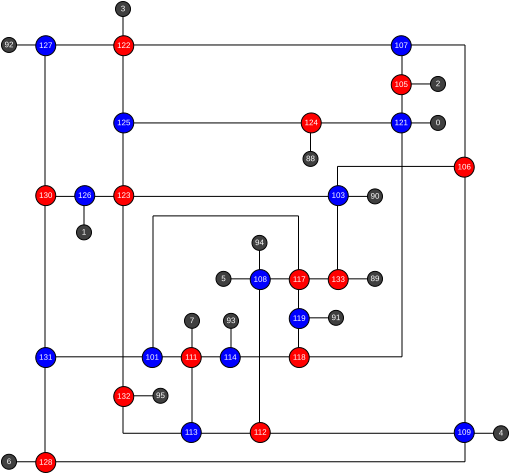

In [5]:
# Perform the layout computation for the fully-reduced, bi-algebraized ZX-graph with enforcing of degree below 4
zxg = PYZX.from_file("../benchmarking/datasets/medio/identity/quick/random-cnots-q8-d32-s3746021966.pyzx.json")
zxg = FullReduction.process(zxg)
zxg = BialgebraReduction.process(zxg)
zxg = NoMoreThanFourEdges.process(zxg)
ogg, attributes, _ = OGDF.from_pyzx_graph(zxg)

for node in ogg.nodes:
    attributes.width[node] *= 20
    attributes.height[node] *= 20

algorithm = ogdf.PlanarizationLayout()
layout = ogdf.OrthoLayout()
layout.__python_owns__ = False  # Needed to avoid C++ segmentation fault when object is destroyed
layout.separation(20.0)
embedder = ogdf.EmbedderMinDepthMaxFaceLayers()
embedder.__python_owns__ = False
algorithm.setEmbedder(embedder)
algorithm.setPlanarLayouter(layout)

algorithm.call(attributes)

print_layout(attributes)

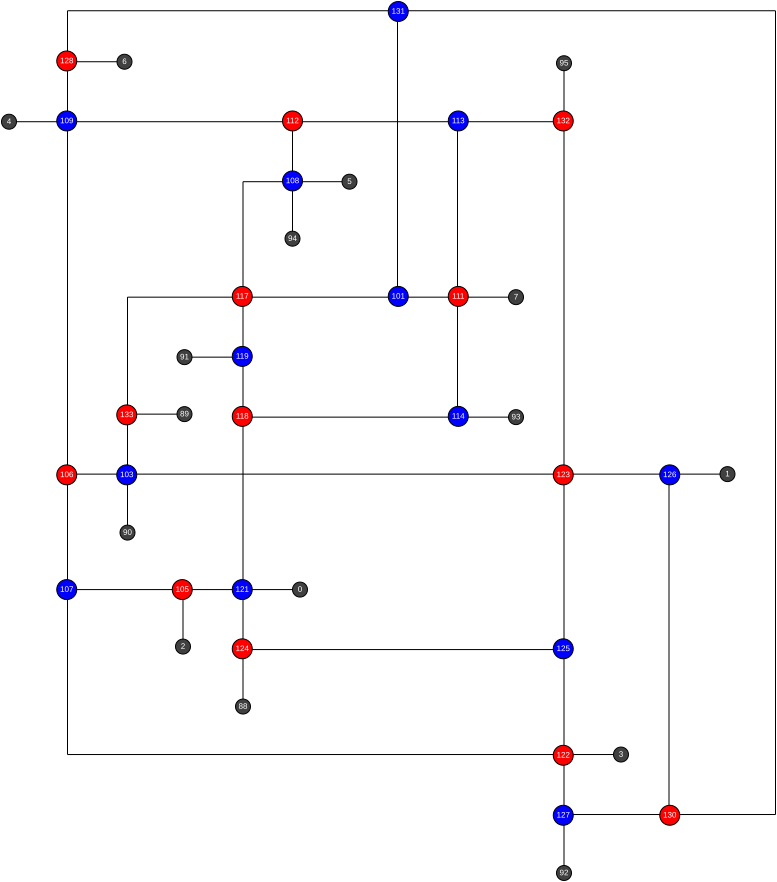

In [10]:
# Convert graph from VZX to OGDF for running layout algorithm
zxg = PYZX.from_file("../benchmarking/datasets/medio/identity/quick/random-cnots-q8-d32-s3746021966.pyzx.json")
zxg = FullReduction.process(zxg)
zxg = BialgebraReduction.process(zxg)
zxg = NoMoreThanFourEdges.process(zxg)
ogg, attributes, _ = OGDF.from_pyzx_graph(zxg)

for node in ogg.nodes:
    attributes.width[node] *= 20
    attributes.height[node] *= 20

algorithm = ogdf.PlanarizationLayout()
layout = ogdf.OrthoLayout()
layout.separation(40.0)
layout.__python_owns__ = False  # Needed to avoid C++ segmentation fault when object is destroyed
algorithm.setPlanarLayouter(layout)

algorithm.call(attributes)

print_layout(attributes)

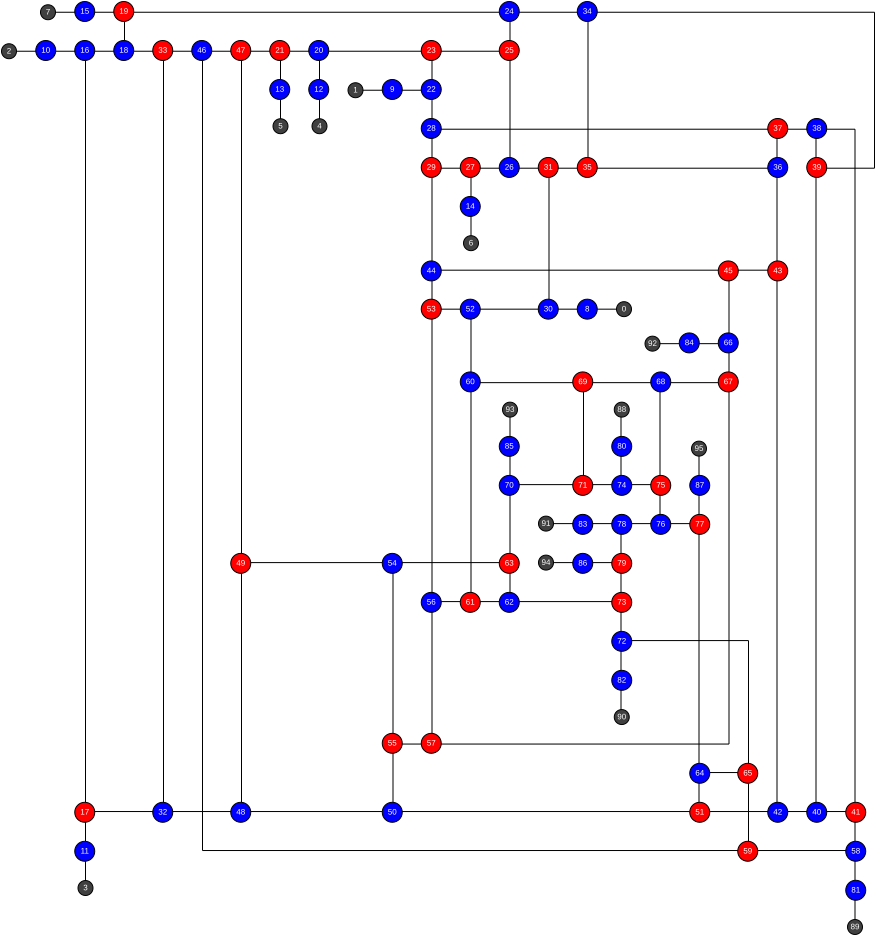

In [7]:
# Perform the layout computation for the unprocessed ZX-graph
zxg = PYZX.from_file("../benchmarking/datasets/medio/identity/quick/random-cnots-q8-d32-s3746021966.pyzx.json")
ogg, attributes, _ = OGDF.from_pyzx_graph(zxg)

for node in ogg.nodes:
    attributes.width[node] *= 20
    attributes.height[node] *= 20

algorithm = ogdf.PlanarizationLayout()
layout = ogdf.OrthoLayout()
layout.__python_owns__ = False  # Needed to avoid C++ segmentation fault when object is destroyed
layout.separation(20.0)
embedder = ogdf.EmbedderMinDepthMaxFaceLayers()
embedder.__python_owns__ = False
algorithm.setEmbedder(embedder)
algorithm.setPlanarLayouter(layout)

algorithm.call(attributes)

print_layout(attributes)